# Exploring Relevant Subreddits

In [2]:
import pandas as pd

## Load Sample Dataset

In [3]:
SAMPLE_POSTS_PATH = "data/prelim_historical_10000_11_11_26.csv"

In [4]:
df_sample_posts = pd.read_csv(SAMPLE_POSTS_PATH)

## Explore Dataset

In [5]:
df_sample_posts["id"].nunique()

10183

In [6]:
df_sample_posts["subreddit"].nunique()

1

In [28]:
df_sample_posts.columns

Index(['id', 'subreddit', 'title', 'selftext', 'url', 'score', 'num_comments',
       'flair', 'created_utc'],
      dtype='object')

### Exploring Title

In [96]:
titles = df_sample_posts["title"]
titles.head(2)

0    Need help with resume
1    Seeking resume advice
Name: title, dtype: object

In [123]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")
stop_words = set(stopwords.words("english"))

def clean_word(word):
    word = word.lower()
    word = "".join([char for char in word if char.isalpha()])
    return word if (word not in stop_words) and len(word) > 0 else None

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/saakethkesireddy/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [124]:
all_title_text = "".join(titles).lower()

In [125]:
title_word_counts = {}
for word in all_title_text.split():
    word = clean_word(word)
    if word in title_word_counts:
        title_word_counts[word] += 1
    else:
        title_word_counts[word] = 1

In [ ]:
title_word_counts_df = pd.DataFrame(title_word_counts.items(), columns=["word", "count"])

In [130]:
title_word_counts_df.dropna(inplace=True)
title_word_counts_df.sort_values(by="count", ascending=False, inplace=True)

In [131]:
relevant_title_word_counts_df = title_word_counts_df[~title_word_counts_df["word"].isin(stop_words)]

In [136]:
relevant_title_word_counts_df.head(25)

,word,count
28,yoe,4416
4,resume,2160
126,engineer,1627
60,unemployed,1297
33,united,1136
49,software,1051
7,student,752
84,analyst,673
15,years,670
34,states,659


### Exploring Text

In [153]:
texts = df_sample_posts["selftext"]

In [154]:
texts.dropna(inplace=True)

In [155]:
all_texts = " ".join(texts)

In [165]:
all_texts_freq = {}
for word in all_texts.split():
    word = clean_word(word)

    if word == "removed" or word == "deleted":
        continue
    
    if word:
        all_texts_freq[word] = all_texts_freq.get(word, 0) + 1

In [169]:
all_text_freqs = pd.DataFrame(all_texts_freq.items(), columns=["word", "count"])
all_text_freqs.sort_values(by="count", ascending=False).head(20)

,word,count
129,im,5871
8,resume,5797
187,job,3047
79,experience,2928
199,ive,2664
20,would,2330
19,roles,2240
32,work,1985
42,looking,1926
65,applying,1894


### Exploring Flairs

In [171]:
flairs = df_sample_posts["flair"]

In [173]:
flairs.value_counts()

flair
Removed: Rule 6 - Use Proper Title/Flair    2873
Technology/Software/IT                      2796
Question                                     903
Finance/Banking                              426
Discussion                                   409
Engineering                                  389
I Have a Question                            343
General/Other Industries                     328
Marketing/Sales                              248
Healthcare/Medical                           209
Retail/Customer Service                      203
Creative/Media                               159
Science/R&D                                  110
Consulting/Professional Services             100
Human Resources                               96
Manufacturing/Operations                      69
Education                                     56
Legal                                         54
Transportation/Logistics                      48
Hospitality                                   47
Academia      

### Exploring Created UTC

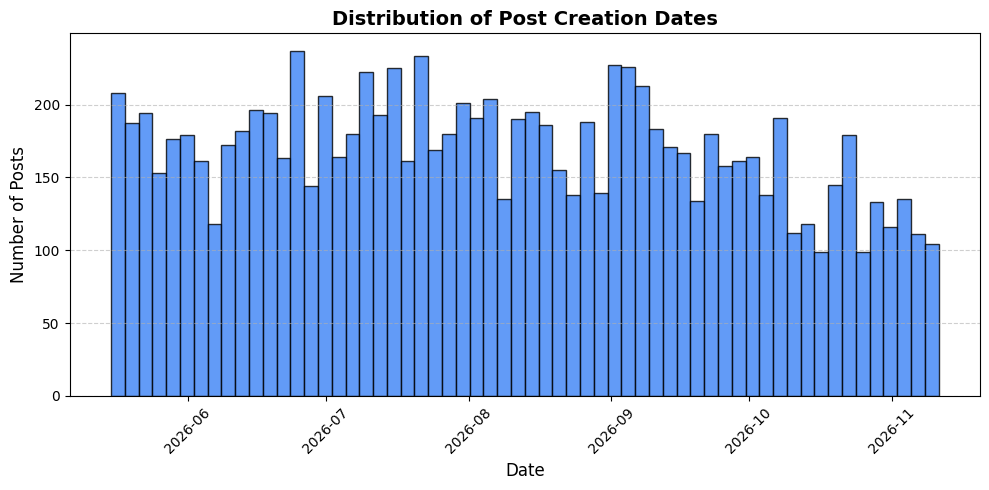

In [180]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Convert unix timestamps (seconds) to datetime
df_sample_posts["created_datetime"] = pd.to_datetime(df_sample_posts["created_utc"], unit="s")

# 2. Plot the histogram
plt.figure(figsize=(10, 5))
plt.hist(df_sample_posts["created_datetime"], bins=60, edgecolor="black", color="#3b82f6", alpha=0.8)

# 3. Add styling and labels
plt.title("Distribution of Post Creation Dates", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Number of Posts", fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()

plt.show()

### Exploring Score

In [182]:
scores = df_sample_posts["score"]

In [185]:
scores.describe()

count    10183.000000
mean         2.053226
std         14.671058
min          0.000000
25%          1.000000
50%          1.000000
75%          1.000000
max       1175.000000
Name: score, dtype: float64

<Axes: >

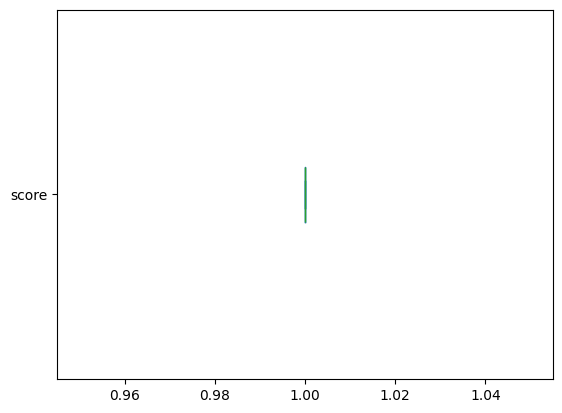

In [190]:
scores.plot.box(showfliers=False, vert=False)

In [192]:
(scores > 1).sum()

np.int64(1705)

In [197]:
(scores > 10).sum()

np.int64(183)

In [198]:
(scores > 100).sum()

np.int64(18)

In [199]:
scores[scores > 1].describe()

count    1705.000000
mean        7.967155
std        35.263530
min         2.000000
25%         2.000000
50%         3.000000
75%         5.000000
max      1175.000000
Name: score, dtype: float64

In [202]:
scores[scores > 10].describe()

count     183.000000
mean       46.409836
std        99.743304
min        11.000000
25%        13.000000
50%        20.000000
75%        38.000000
max      1175.000000
Name: score, dtype: float64

In [205]:
scores[scores > 100].describe()

count      18.000000
mean      234.166667
std       248.029232
min       103.000000
25%       118.000000
50%       151.500000
75%       240.750000
max      1175.000000
Name: score, dtype: float64

### Exploring Comments

In [207]:
comments = df_sample_posts["num_comments"]

In [212]:
comments.describe()

count    10183.000000
mean         2.914072
std          6.730551
min          0.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        271.000000
Name: num_comments, dtype: float64

In [213]:
comments[comments > 1].describe()

count    3690.000000
mean        6.315718
std        10.336743
min         2.000000
25%         2.000000
50%         4.000000
75%         7.000000
max       271.000000
Name: num_comments, dtype: float64

In [214]:
comments[comments > 10].describe()

count    470.000000
mean      21.700000
std       23.175179
min       11.000000
25%       12.000000
50%       15.000000
75%       23.000000
max      271.000000
Name: num_comments, dtype: float64

In [216]:
comments[comments > 100].describe()

count      5.000000
mean     204.000000
std       65.030762
min      137.000000
25%      141.000000
50%      204.000000
75%      267.000000
max      271.000000
Name: num_comments, dtype: float64

### Exploring URL

In [229]:
df_sample_posts["url"].str.split("/").str[-1].str.split(".").str[-1].value_counts().head(20)

url
                                        3658
jpeg                                    2771
png                                     1932
com                                        6
gif                                        5
app                                        4
FkH9bW5S                                   4
view?usp=drivesdk                          3
1211801772?share=copy&fl=sv&fe=ci          3
view?usp=sharing                           3
524AF2A6-E00D-46B5-A66E-A56EBB58FA75       3
dMGBX1y                                    3
1211801772                                 2
1v65xsp                                    2
8tcSjgY                                    2
ocC30Oh                                    2
UOcu1Rg                                    2
edit?usp=sharing                           2
o7sa95y5da1h1                              2
SkillNestHub1                              2
Name: count, dtype: int64

In [231]:
df_sample_posts["url"].str.contains("jpeg").value_counts()

url
False    7244
True     2771
Name: count, dtype: int64

In [232]:
df_sample_posts["url"].str.contains("png").value_counts()

url
False    8082
True     1933
Name: count, dtype: int64

## Determining Relevant Dataset

In [240]:
# sort by comments, score
sorted_df_sample_posts = df_sample_posts.sort_values(by=["num_comments", "score"], ascending=[False, False])
sorted_df_sample_posts.shape

(10183, 10)

In [243]:
# keep only ones with a valid attachment (image)
contains_image = df_sample_posts["url"].str.contains("jpeg|png")
sorted_df_sample_posts_w_image = sorted_df_sample_posts[contains_image == True]
sorted_df_sample_posts_w_image.shape

(4704, 10)

In [285]:
# remove posts with no score or comments
removed_invalids = sorted_df_sample_posts_w_image[(sorted_df_sample_posts_w_image["score"] > 0) & (sorted_df_sample_posts_w_image["num_comments"] > 10)].dropna()
removed_invalids.shape

(106, 10)

In [286]:
valid_post_cohort = removed_invalids

In [287]:
valid_post_cohort.to_csv("prelim_filtered_posts_115_11_12_26.csv", index=False)